# ДЗ 1. Предсказание цены подержанного автомобиля (Craigslist)

Датасет: https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data

## 0. Постановка задачи

У нас около 427 тысяч объявлений о продаже подержанных машин с сайта Craigslist (США), собранных в апреле и мае 2021 года. Каждая строка описывает одно объявление: цену, характеристики машины, местоположение продавца и несколько служебных полей.

**Задача:** по характеристикам автомобиля предсказать его цену `price` в долларах. Цена выражается вещественным числом, так что перед нами задача **регрессии** (обучение с учителем).

**Какие есть признаки:**

| группа | признаки |
|---|---|
| количественные | `year` (год выпуска), `odometer` (пробег в милях), `lat`, `long` (координаты) |
| категориальные, мало значений | `condition` (состояние), `cylinders` (число цилиндров), `fuel` (топливо), `title_status` (статус документов), `transmission` (коробка передач), `drive` (привод), `size` (размер), `type` (тип кузова), `paint_color` (цвет) |
| категориальные, много значений | `manufacturer` (42 марки), `model` (около 30 тысяч значений, свободный текст), `region` (404 региона), `state` (51 штат) |
| служебные, о цене ничего не говорят | `id`, `url`, `region_url`, `image_url`, `VIN`, `county` (всегда пуст), `posting_date` (все объявления за один месяц) |

**Как будем мерить качество.** Цены разбросаны от сотен долларов до сотен тысяч. Ошибиться на 3 000 $ для машины за 5 000 $ гораздо хуже, чем для машины за 80 000 $. Поэтому главной метрикой выберем **RMSLE**, среднеквадратичную ошибку в логарифмах цены: по смыслу она показывает типичную *относительную* ошибку. Для наглядности будем выводить ещё MAE в долларах и коэффициент детерминации $R^2$.

## 1. Чтение данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

In [2]:
# description (длинный текст объявления) не нужен — без него чтение быстрее
df = pd.read_csv('data/vehicles.csv', usecols=lambda c: c != 'description')
df.shape

(426880, 25)

In [3]:
df.head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 25 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  str    
 2   region        426880 non-null  str    
 3   region_url    426880 non-null  str    
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  str    
 7   model         421603 non-null  str    
 8   condition     252776 non-null  str    
 9   cylinders     249202 non-null  str    
 10  fuel          423867 non-null  str    
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  str    
 13  transmission  424324 non-null  str    
 14  VIN           265838 non-null  str    
 15  drive         296313 non-null  str    
 16  size          120519 non-null  str    
 17  type          334022 non-null  str    
 18  paint_color   2

Числовые здесь только `price`, `year`, `odometer`, `lat` и `long`, остальные признаки строковые. Пропуски есть во многих столбцах (разберём их в разделе 5), а `county` и вовсе пустой.

## 2. Разбиение на обучающую и тестовую выборки

**Но сначала разберёмся с дубликатами.** На Craigslist одну и ту же машину часто выкладывают много раз: повторно или сразу в нескольких регионах. Представим, что копии одной машины попали и в обучающую, и в тестовую выборку. Тогда метод ближайших соседей просто найдёт эту же машину среди обучающих объектов, и ошибка на тесте получится обманчиво маленькой. Целевую переменную удаление дубликатов не использует, поэтому делать его до разбиения можно и нужно.

Дубликатами будем считать объявления, у которых совпадают все характеристики машины, включая точный пробег. Цену и местоположение не сравниваем: перевыложенное объявление вполне может оказаться в другом регионе или с другой ценой. Ещё уберём повторы VIN и заодно выбросим служебные столбцы.

In [5]:
print('Объявления опубликованы с', df['posting_date'].min()[:10], 'по', df['posting_date'].max()[:10])

service_cols = ['id', 'url', 'region_url', 'image_url', 'county', 'posting_date', 'VIN']
car_cols = ['year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer',
            'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color']

n_before = len(df)
df = df.drop_duplicates(subset=car_cols)
df = df[~(df['VIN'].notna() & df['VIN'].duplicated())]
df = df.drop(columns=service_cols)
print(f'Удалено дубликатов: {n_before - len(df)} ({(n_before - len(df)) / n_before:.1%}), осталось {len(df)}')

Объявления опубликованы с 2021-04-04 по 2021-05-04


Удалено дубликатов: 189106 (44.3%), осталось 237774


In [6]:
train, test = train_test_split(df, test_size=0.25, random_state=RANDOM_STATE)
train.shape, test.shape

((178330, 18), (59444, 18))

Тестовую выборку (25%) откладываем в сторону. Все решения (границы выбросов, медианы для пропусков, кодирование категорий, параметры нормализации, выбор $k$) принимаем **только по обучающей выборке**, а к тестовой лишь применяем найденные правила.

## 3. Визуализация и основные характеристики

In [7]:
train.describe()

,price,year,odometer,lat,long
count,1.783300e+05,177903.000000,1.766590e+05,177248.000000,177248.000000
mean,1.147559e+05,2009.292446,1.128525e+05,38.378319,-95.789617
std,1.603389e+07,10.838488,2.488283e+05,5.988482,18.756342
min,0.000000e+00,1900.000000,0.000000e+00,-84.122245,-159.827728
25%,4.900000e+03,2006.000000,5.259500e+04,34.422800,-114.140400
50%,9.995000e+03,2012.000000,1.000000e+05,39.140251,-90.339546
75%,1.975000e+04,2016.000000,1.460000e+05,42.334900,-81.265946
max,3.736929e+09,2022.000000,1.000000e+07,82.252826,173.885502


In [8]:
train.describe(exclude='number')

,region,manufacturer,model,condition,cylinders,fuel,title_status,transmission,drive,size,type,paint_color,state
count,178330,170468,175720,108161,114918,177140,175690,177446,127734,63908,132747,125237,178330
unique,404,42,24083,6,8,5,6,3,3,4,13,12,51
top,phoenix,ford,f-150,excellent,4 cylinders,gas,clean,automatic,4wd,full-size,sedan,white,ca
freq,1999,29165,3270,50601,41033,157203,167453,154981,54122,32381,37520,30538,22481


In [9]:
print(f"price = 0:      {(train['price'] == 0).mean():.1%} объявлений")
print(f"price < 500 $:  {(train['price'] < 500).mean():.1%}")
print(f"price > 200k $: {(train['price'] > 200_000).sum()} объявлений")

price = 0:      6.9% объявлений
price < 500 $:  8.9%
price > 200k $: 64 объявлений


**Что видно из таблиц.**

С ценой явно что-то не так. Медиана около 10 000 $, а среднее почти 115 000 $ при стандартном отклонении в 16 миллионов. Виноваты несколько абсурдных значений, самое большое из которых 3.7 миллиарда долларов. При этом у 6.9% объявлений цена равна нулю, а у 8.9% она меньше 500 $.

С пробегом похожая история: медиана 100 000 миль, а максимум 10 миллионов. Год выпуска меняется от 1900 до 2022, половина машин выпущена с 2006 по 2016 год. Координаты местами уходят далеко за пределы США (широта до −84°, долгота до +174°).

Среди категориальных признаков чаще всего встречаются `ford`, `gas`, `clean`, `automatic`, `4wd`, `sedan` и `white`. У `model` больше 24 тысяч разных значений, у `region` их 404.

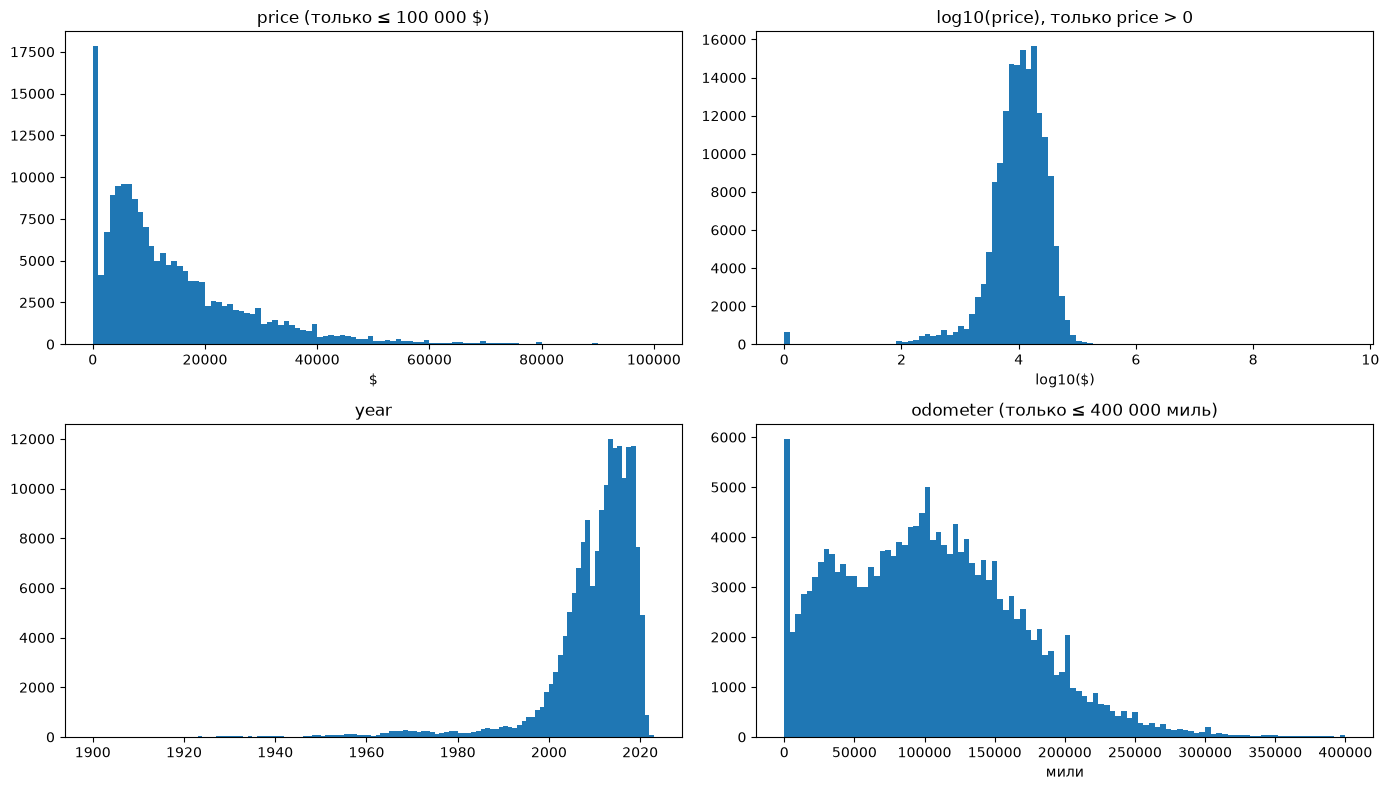

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
price = train['price']
axes[0, 0].hist(price[price <= 100_000], bins=100)
axes[0, 0].set(title='price (только ≤ 100 000 $)', xlabel='$')
axes[0, 1].hist(np.log10(price[price > 0]), bins=100)
axes[0, 1].set(title='log10(price), только price > 0', xlabel='log10($)')
axes[1, 0].hist(train['year'].dropna(), bins=np.arange(1900, 2024))
axes[1, 0].set(title='year')
axes[1, 1].hist(train['odometer'][train['odometer'] <= 400_000], bins=100)
axes[1, 1].set(title='odometer (только ≤ 400 000 миль)', xlabel='мили')
plt.tight_layout()
plt.show()

Цена сильно скошена вправо, и возле нуля торчит отдельный пик из нулевых и символических цен. А вот логарифм цены распределён почти симметрично, «колоколом». Слева у него хвост из тех же символических цен, справа единичные гигантские значения.

Большинство машин выпущено с 2000 по 2020 год, но есть и длинный хвост старых коллекционных автомобилей. Провал около 2009 года, скорее всего, след кризиса 2008 года, когда новых машин продавали меньше.

Пробег в основном образует широкий горб с медианой около 100 000 миль. Есть пик в нуле (новые машины и «заглушки») и пики на круглых значениях вроде 100 000 и 200 000: продавцы любят округлять.

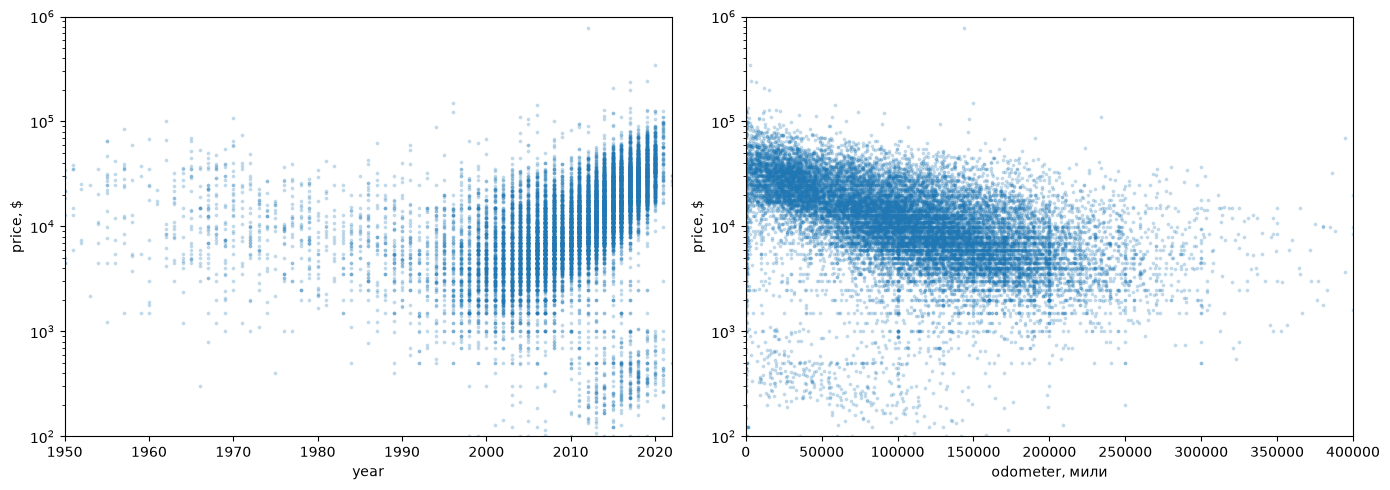

In [11]:
sample = train[train['price'] > 0].sample(20_000, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(sample['year'], sample['price'], s=3, alpha=0.2)
axes[0].set(xlabel='year', ylabel='price, $', yscale='log', xlim=(1950, 2022), ylim=(100, 1e6))
axes[1].scatter(sample['odometer'], sample['price'], s=3, alpha=0.2)
axes[1].set(xlabel='odometer, мили', ylabel='price, $', yscale='log', xlim=(0, 400_000), ylim=(100, 1e6))
plt.tight_layout()
plt.show()

Цена растёт с годом выпуска (у машин новее 1995 года почти линейно в логарифмической шкале) и падает с пробегом. У машин старше примерно 1980 года связь с годом пропадает. Это коллекционные автомобили, и с возрастом они не дешевеют. Ещё заметна полоса цен от 100 до 1 000 $ у почти новых машин. Настоящими ценами это быть не может: скорее всего, продавцы указали ежемесячный платёж или первый взнос.

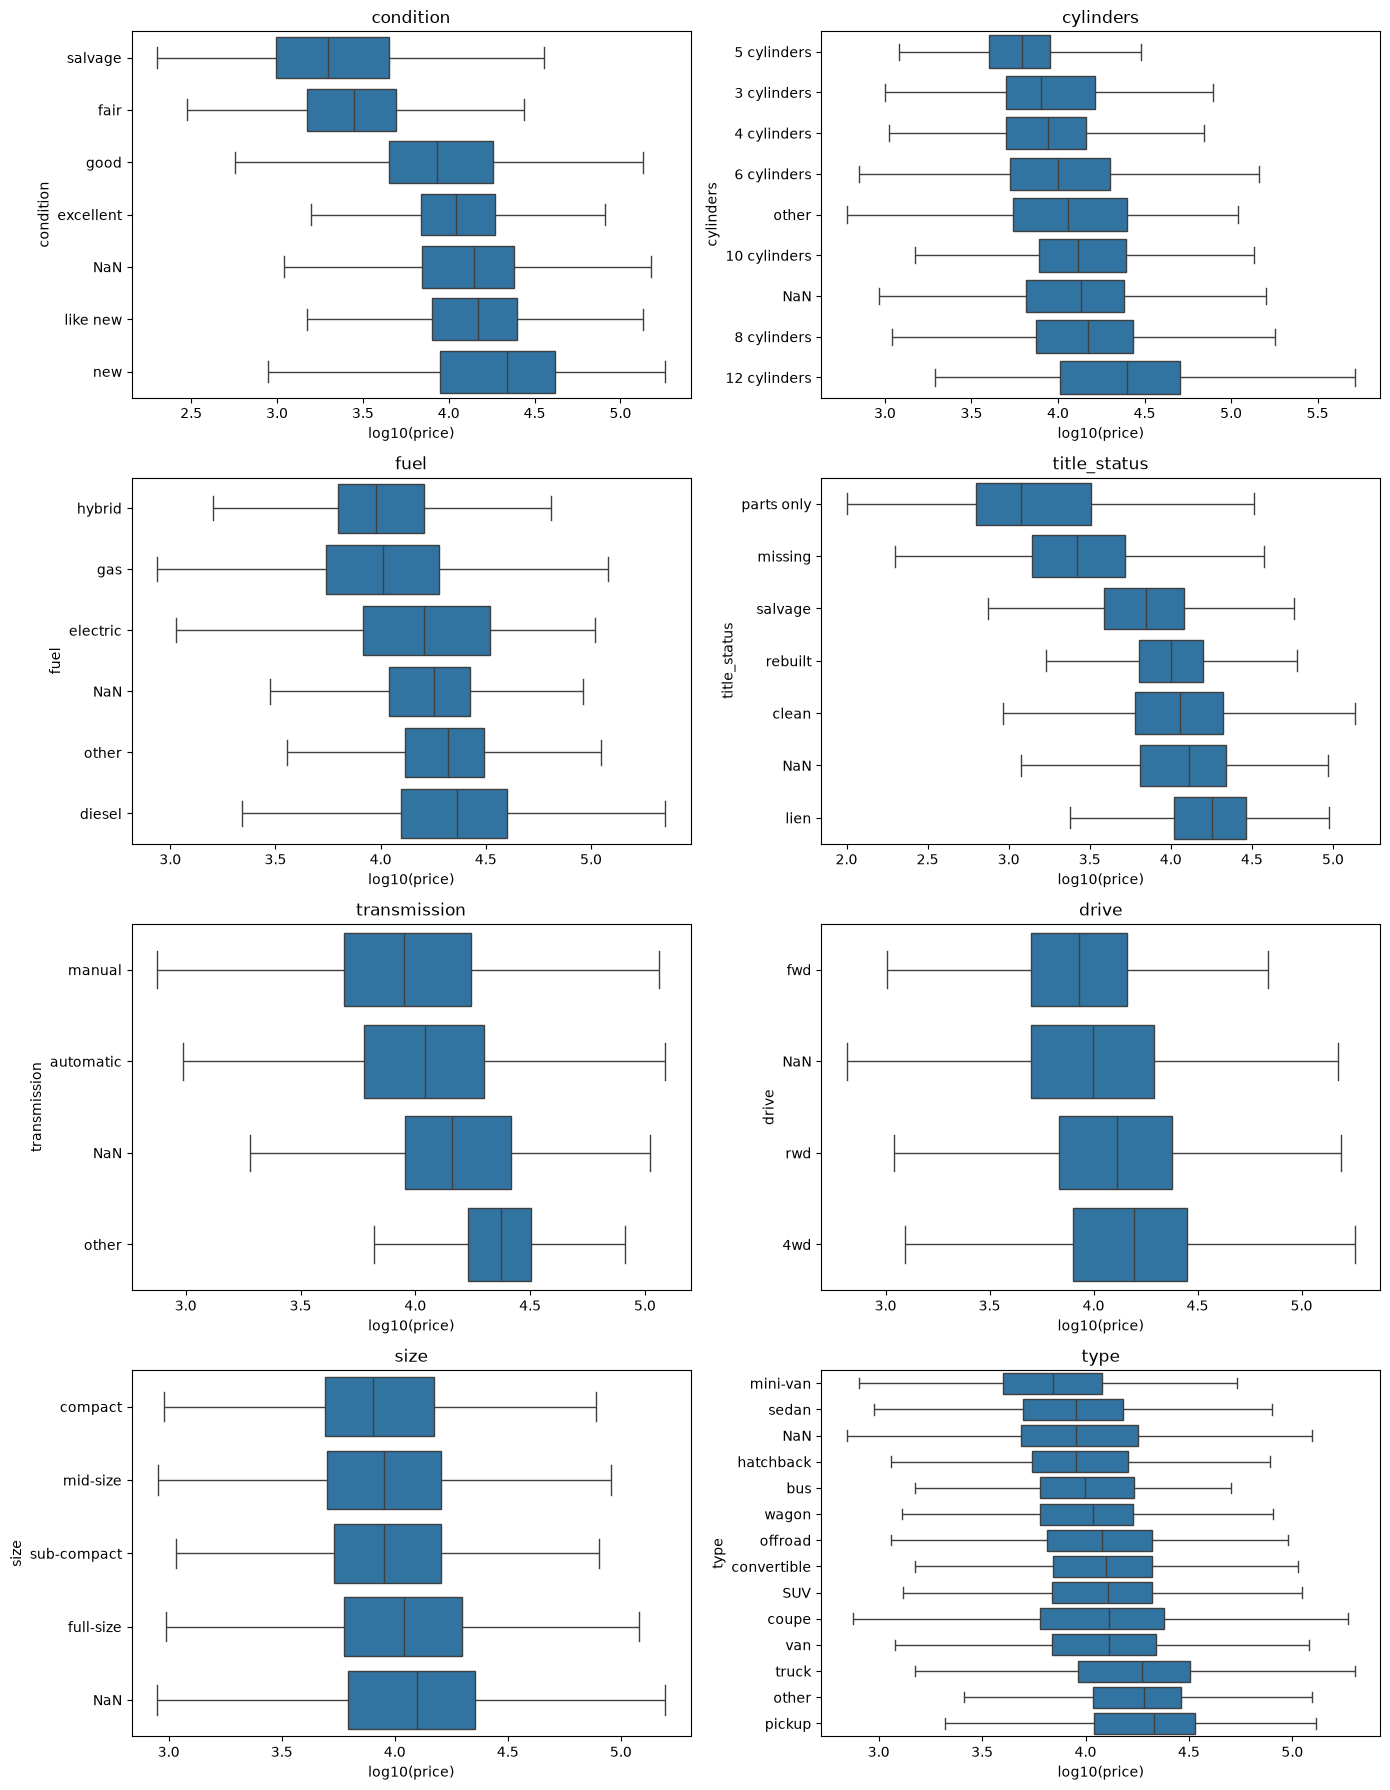

In [12]:
box_cols = ['condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type']
valid = train[train['price'].between(100, 1_000_000)]
log_price = np.log10(valid['price']).rename('log10(price)')

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for ax, col in zip(axes.ravel(), box_cols):
    values = valid[col].fillna('NaN')
    order = log_price.groupby(values).median().sort_values().index
    sns.boxplot(x=log_price, y=values, order=order, showfliers=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Что видно по ящикам с усами:
- Состояние влияет так, как и ожидалось: цена растёт от `salvage` и `fair` к `like new` и `new`.
- По статусу документов заметно дешевле машины на запчасти (`parts only`), без документов (`missing`) и после серьёзных повреждений (`salvage`).
- Дизельные машины, в основном большие пикапы, дороже бензиновых. Самая дорогая группа по коробке передач `other`; похоже, это в основном дилерские объявления о свежих машинах.
- Полный привод дороже переднего. Пикапы и грузовики дороже, а мини-вэны, седаны и хэтчбеки дешевле. И чем больше цилиндров, тем в среднем дороже машина.
- Самое интересное: у пропусков (`NaN`) в каждом признаке своё распределение цены, не похожее на остальные. Значит, сам факт пропуска что-то говорит о машине. Учтём это в разделе 5.

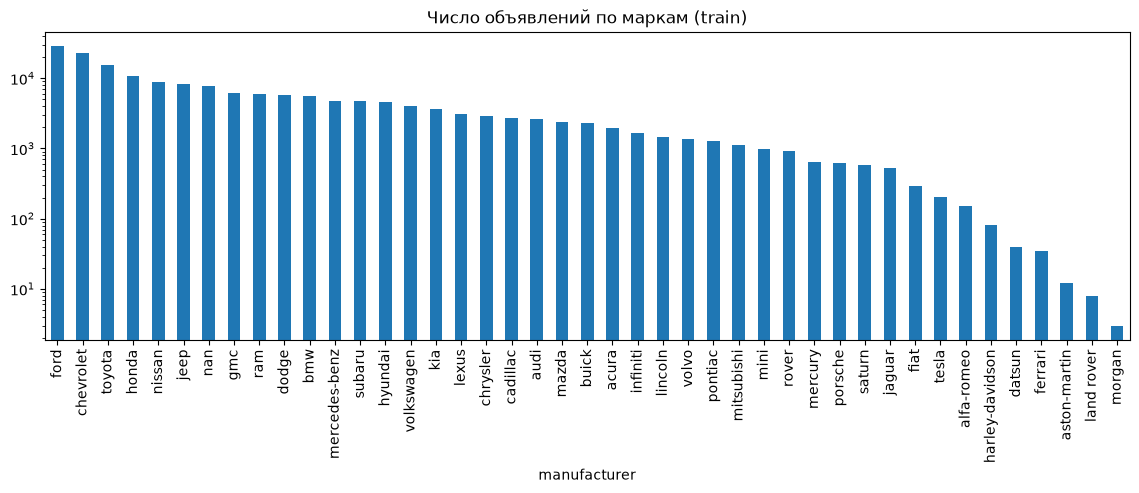

In [13]:
counts = train['manufacturer'].value_counts(dropna=False)
plt.figure(figsize=(14, 4))
counts.plot.bar()
plt.title('Число объявлений по маркам (train)')
plt.yscale('log')
plt.show()

Шкала здесь логарифмическая, и всё равно видно, насколько неравномерно представлены марки. У Ford и Chevrolet десятки тысяч объявлений, а у Ferrari, Aston Martin и Morgan счёт идёт на десятки и единицы. Вернёмся к этому в разделе 11.

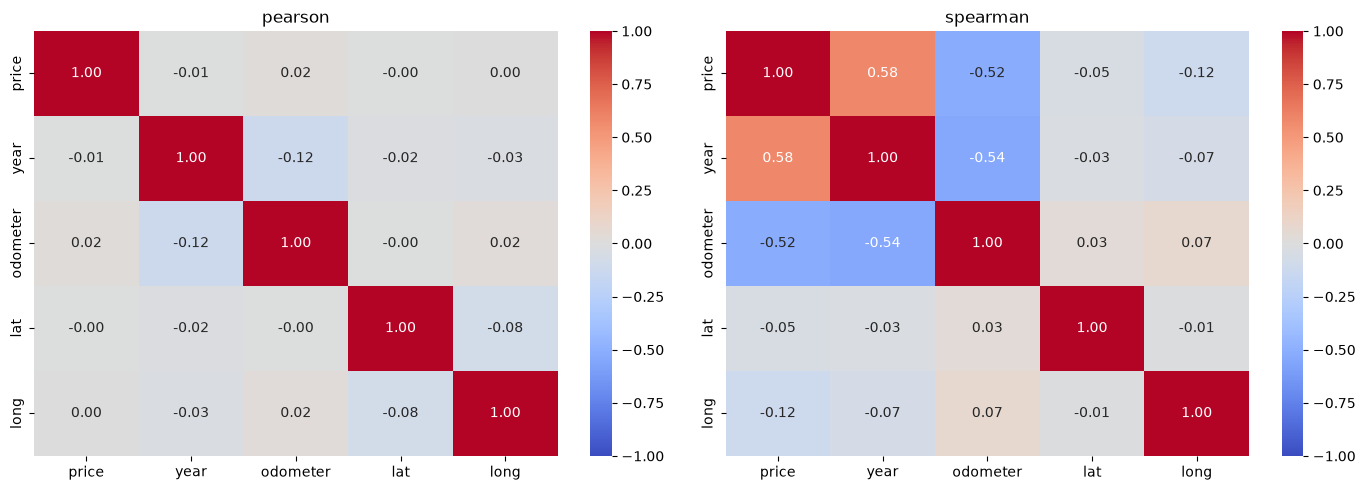

In [14]:
num_cols = ['price', 'year', 'odometer', 'lat', 'long']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = train.loc[train['price'] > 0, num_cols].corr(method=method)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(method)
plt.tight_layout()
plt.show()

Корреляция Пирсона на сырых данных ничего не показывает: выбросы вроде цены в миллиарды и пробега в миллионы миль сводят её почти к нулю. Ранговая корреляция Спирмена к выбросам устойчива, и с ней картина понятная. Цена растёт с годом выпуска (0.58) и падает с пробегом (−0.52), а у старых машин пробег больше (−0.54 между `year` и `odometer`). С координатами цена почти не связана. Слабая отрицательная связь с долготой означает, что на западе машины чуть дороже.

## 4. Выбросы

**Цена.** Нулевые и копеечные цены не имеют отношения к стоимости машины: так пишут «цена по запросу», ежемесячный платёж или первый взнос. Значения вроде 1 111 111 111 $ похожи на шутки или опечатки. Границы найдём по правилу полутора межквартильных размахов, но применим его к **логарифму** цены. В обычной шкале распределение слишком скошено, и правило отрезало бы много нормальных дорогих машин. Квартили считаем по обучающей выборке, только по объявлениям с положительной ценой.

Допустимые цены: 911 – 132,691 $
Вне диапазона: 10.0% объектов train


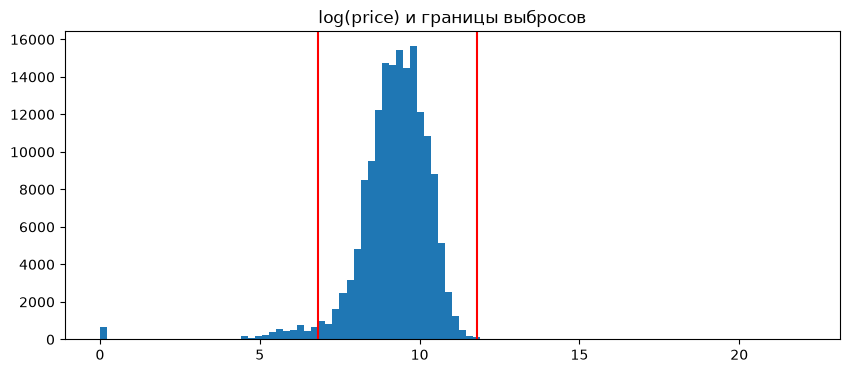

In [15]:
log_p = np.log(train.loc[train['price'] > 0, 'price'])
q1, q3 = log_p.quantile([0.25, 0.75])
iqr = q3 - q1
PRICE_MIN, PRICE_MAX = np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)
print(f'Допустимые цены: {PRICE_MIN:,.0f} – {PRICE_MAX:,.0f} $')
print(f"Вне диапазона: {(~train['price'].between(PRICE_MIN, PRICE_MAX)).mean():.1%} объектов train")

plt.figure(figsize=(10, 4))
plt.hist(log_p, bins=100)
for bound in (PRICE_MIN, PRICE_MAX):
    plt.axvline(np.log(bound), color='r')
plt.title('log(price) и границы выбросов')
plt.show()

**Координаты.** Большая часть точек складывается в контур США, но некоторые объявления оказались в Европе, Азии, посреди океана или с перепутанным знаком долготы:

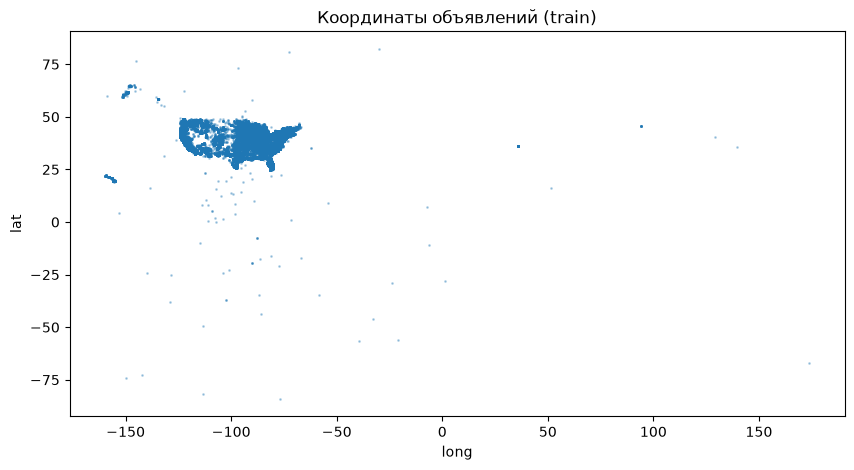

In [16]:
plt.figure(figsize=(10, 5))
plt.scatter(train['long'], train['lat'], s=1, alpha=0.3)
plt.xlabel('long')
plt.ylabel('lat')
plt.title('Координаты объявлений (train)')
plt.show()

**Как обрабатываем выбросы:**
- Если `price` выходит за найденный диапазон, объект удаляем. Настоящей цены у такого объекта по сути нет, поэтому удаляем его и из тестовой выборки: ошибка на нём ничего не скажет о качестве модели. Получается, что наша модель рассчитана на машины с ценой из этого диапазона.
- Пробег больше 500 000 миль нереален (это заглушки 999 999, 1 111 111, 10 000 000). Пробег меньше 100 миль у машины старше 2019 года тоже заглушка (0 или 1). Такие объекты не удаляем, а заменяем значение на пропуск и заполняем его в разделе 5. Так же можно будет поступить с любым новым объявлением.
- Координаты за пределами прямоугольника, который охватывает США вместе с Аляской и Гавайями, тоже заменяем на пропуск.
- Старые машины (до 1980 года) оставляем. Это не ошибки, а настоящие коллекционные автомобили.

In [17]:
def remove_outliers(d):
    d = d[d['price'].between(PRICE_MIN, PRICE_MAX)].copy()
    d.loc[d['odometer'] > 500_000, 'odometer'] = np.nan
    d.loc[(d['odometer'] < 100) & (d['year'] <= 2018), 'odometer'] = np.nan
    outside_us = ~(d['lat'].between(18, 72) & d['long'].between(-170, -60))
    d.loc[outside_us, ['lat', 'long']] = np.nan
    return d


def outlier_stats(before, after):
    same = before.loc[after.index]
    return {'удалено объектов (цена)': len(before) - len(after),
            'пробег -> NaN': after['odometer'].isna().sum() - same['odometer'].isna().sum(),
            'координаты -> NaN': after['lat'].isna().sum() - same['lat'].isna().sum(),
            'осталось объектов': len(after)}


train_clean, test_clean = remove_outliers(train), remove_outliers(test)
display(pd.DataFrame({'train': outlier_stats(train, train_clean), 'test': outlier_stats(test, test_clean)}))
train, test = train_clean, test_clean
train[['price', 'year', 'odometer', 'lat', 'long']].describe()

,train,test
удалено объектов (цена),17770,5930
пробег -> NaN,2117,684
координаты -> NaN,66,23
осталось объектов,160560,53514


,price,year,odometer,lat,long
count,160560.000000,160142.000000,157722.000000,159641.000000,159641.000000
mean,15726.516984,2008.917261,106955.288482,38.381433,-95.360330
std,13578.557853,10.953210,64283.199881,5.903635,18.403056
min,918.000000,1900.000000,0.000000,18.852034,-159.719900
25%,6195.000000,2006.000000,57724.500000,34.422800,-112.019144
50%,11795.500000,2011.000000,103000.000000,39.157300,-89.806200
75%,20995.000000,2015.000000,148216.000000,42.300700,-81.204500
max,131950.000000,2022.000000,500000.000000,64.993698,-61.944582


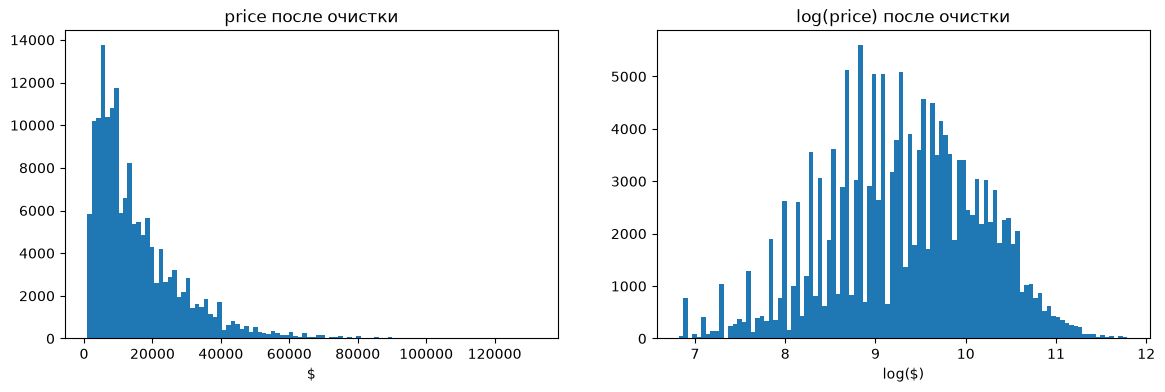

Асимметрия: price 2.09, log(price) -0.23


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(train['price'], bins=100)
axes[0].set(title='price после очистки', xlabel='$')
axes[1].hist(np.log(train['price']), bins=100)
axes[1].set(title='log(price) после очистки', xlabel='log($)')
plt.show()
print(f"Асимметрия: price {train['price'].skew():.2f}, log(price) {np.log(train['price']).skew():.2f}")

Даже после очистки цена сильно скошена (асимметрия 2.09), а её логарифм распределён почти симметрично (−0.23). «Гребёнка» на гистограмме логарифма появилась из-за круглых цен вроде 5 000 $ или 9 995 $.

Поэтому дальше будем предсказывать **log(price)**. Тогда ошибка в логарифмах будет соответствовать относительной ошибке, как мы и хотели в разделе 0, а редкие дорогие машины не будут перетягивать на себя ни ошибку, ни усреднение цен соседей. Прогноз в долларах получим как $e^{\hat y}$.

## 5. Пропущенные значения

In [19]:
missing = pd.DataFrame({'пропусков': train.isna().sum(), 'доля': train.isna().mean().round(3)})
missing[missing['пропусков'] > 0].sort_values('доля', ascending=False)

,пропусков,доля
size,100836,0.628
condition,59253,0.369
cylinders,54620,0.340
drive,44403,0.277
paint_color,44524,0.277
type,40815,0.254
manufacturer,7020,0.044
odometer,2838,0.018
model,2285,0.014
title_status,2103,0.013


In [20]:
missing_share = train[['condition', 'cylinders', 'drive', 'paint_color', 'type']].isna()
print('Доля объявлений, где одновременно пропущены condition, cylinders, drive, paint_color, type:',
      f'{missing_share.all(axis=1).mean():.1%}')
print('Медианная цена, когда condition пропущен / заполнен:',
      train.groupby(train['condition'].isna())['price'].median().to_dict())

Доля объявлений, где одновременно пропущены condition, cylinders, drive, paint_color, type: 9.9%
Медианная цена, когда condition пропущен / заполнен: {False: 9999.0, True: 14500.0}


Больше всего пропусков в `size` (63%), `condition` (37%) и `cylinders` (34%). У `drive`, `paint_color` и `type` пропущена примерно четверть значений.

Удалить строки с пропусками не получится: пришлось бы выбросить большую часть данных. Удалять столбцы тоже жалко, ведь там, где признаки заполнены, они полезны.

К тому же пропуски не случайны. У 9.9% объявлений пропущены сразу пять признаков; так обычно выглядят шаблонные, часто дилерские, объявления. А машины без указанного `condition` в среднем дороже: медиана 14 500 $ против 10 000 $. Поэтому в категориальных признаках пропуск станет **отдельной категорией `unknown`**, и kNN сможет пользоваться самим фактом пропуска.

С числовыми признаками поступим так:
- `lat` и `long` (0.6% пропусков) заполним медианой координат по штату объявления. Штат известен всегда, и так получится точнее, чем с общей медианой.
- `year` и `odometer` (0.3% и 1.8%) заполним медианой по train.
- `cylinders` пока получит значение `unknown`, а в число мы его превратим в разделе 6.

In [21]:
unknown_cols = ['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status',
                'transmission', 'drive', 'size', 'type', 'paint_color']
state_coords = train.groupby('state')[['lat', 'long']].median()
num_medians = train[['year', 'odometer']].median()


def fill_missing(d):
    d = d.copy()
    d[unknown_cols] = d[unknown_cols].fillna('unknown')
    for col in ['lat', 'long']:
        d[col] = d[col].fillna(d['state'].map(state_coords[col]))
    return d.fillna(num_medians)


train, test = fill_missing(train), fill_missing(test)
print('Пропусков осталось: train', train.isna().sum().sum(), ', test', test.isna().sum().sum())

Пропусков осталось: train 0 , test 0


## 6. Категориальные признаки

Разберём признаки по очереди.

**`cylinders`** по смыслу числовой и упорядоченный, так что «6 cylinders» превращаем просто в 6. Значения `other` и `unknown` заменяем медианой по train.

**`model`** записан свободным текстом, и в train у него больше 22 тысяч вариантов: «f-150», «f150 xlt supercrew», «F-150 Lariat» и так далее. Сначала нормализуем его: переводим в нижний регистр, берём первое слово и приписываем впереди марку (`ford f-150`). Кодировать такой признак через one-hot плохо. Получились бы тысячи столбцов, почти всегда равных нулю, а лишние измерения для kNN губительны (проклятие размерности). Поэтому используем **target encoding** и заменяем каждую модель средним log(price) её объявлений в train. Для редких моделей среднее сглаживаем к общему среднему:
$$\text{кодировка} = \frac{n \cdot \text{среднее по модели} + m \cdot \text{общее среднее}}{n + m}, \quad m = 10.$$
Режим `smooth='auto'` в sklearn тут не подходит: модель с единственным объявлением он не сглаживает вовсе, потому что её внутригрупповая дисперсия равна нулю. На самой обучающей выборке кодировка считается по схеме кросс-валидации, чтобы цена объекта не попадала в его собственный признак.

**`manufacturer`, `condition`, `fuel`, `title_status`, `transmission`, `drive`, `size`, `type`, `paint_color`** принимают немного значений, их кодируем через **one-hot**. Хотя `condition` по смыслу порядковый, у 37% объявлений он неизвестен, и `unknown` в этот порядок никак не встраивается. Да и непонятно, насколько `good` «далеко» от `excellent`. Так что его тоже кодируем через one-hot. Категории, которые встречаются в train реже 30 раз, объединяем в одну общую «редкую».

**`region` и `state`** не используем. Местоположение уже описывают два числа `lat` и `long`, а эти признаки добавили бы 404 и 51 бинарный столбец.

In [22]:
def add_features(d):
    d = d.copy()
    d['cylinders'] = pd.to_numeric(d['cylinders'].str.extract(r'(\d+)')[0])
    d['model_key'] = d['manufacturer'] + ' ' + d['model'].str.lower().str.split().str[0].fillna('')
    return d


train, test = add_features(train), add_features(test)
cylinders_median = train['cylinders'].median()
train['cylinders'] = train['cylinders'].fillna(cylinders_median)
test['cylinders'] = test['cylinders'].fillna(cylinders_median)

print('Уникальных model:', train['model'].nunique(), '-> model_key:', train['model_key'].nunique())
train['model_key'].value_counts().head(10)

Уникальных model: 22140 -> model_key: 4474


model_key
chevrolet silverado    5499
ford f-150             3700
jeep wrangler          2595
honda accord           2551
ram 1500               2485
honda civic            2444
toyota camry           2371
gmc sierra             2275
ford escape            1842
ford f150              1751
Name: count, dtype: int64

In [23]:
num_features = ['year', 'odometer', 'cylinders', 'lat', 'long']
te_features = ['model_key']
ohe_features = ['manufacturer', 'condition', 'fuel', 'title_status', 'transmission',
                'drive', 'size', 'type', 'paint_color']

# целевая переменная — логарифм цены (см. раздел 4)
y_train = np.log(train['price'].to_numpy())
y_test = np.log(test['price'].to_numpy())

ohe = OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False)
ohe.fit(train[ohe_features])
print('Бинарных признаков после one-hot:', len(ohe.get_feature_names_out()))

Бинарных признаков после one-hot: 100


In [24]:
def make_target_encoder():
    return TargetEncoder(target_type='continuous', smooth=10,
                         cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))


te = make_target_encoder().fit(train[te_features], y_train)

keys = train['model_key']
encoding = pd.DataFrame({
    'объявлений': keys.value_counts(),
    'средняя цена, $': np.exp(pd.Series(y_train, index=train.index).groupby(keys).mean()),
    'цена по кодировке, $': np.exp(pd.Series(te.encodings_[0], index=te.categories_[0])),
}).round(0)
popular = encoding.nlargest(5, 'объявлений')
rare = encoding[encoding['объявлений'] <= 2].sample(5, random_state=RANDOM_STATE)
pd.concat([popular, rare])

,объявлений,"средняя цена, $","цена по кодировке, $"
chevrolet silverado,5499,18628.0,18611.0
ford f-150,3700,17006.0,16986.0
jeep wrangler,2595,20324.0,20278.0
honda accord,2551,7341.0,7353.0
ram 1500,2485,18439.0,18402.0
unknown element,2,16622.0,11962.0
mercedes-benz 220s,1,22500.0,11934.0
ford f650xlt,1,49500.0,12821.0
unknown thunder,1,17873.0,11687.0
unknown ford*,2,8655.0,10729.0


In [25]:
print(f'Общее среднее, пересчитанное в доллары: {np.exp(y_train.mean()):,.0f} $')

Общее среднее, пересчитанное в доллары: 11,201 $


У популярных моделей кодировка почти совпадает со средней ценой. А у моделей с одним или двумя объявлениями она сильно сдвинута к общему среднему, около 11 200 $. Например, единственный в train `ford f650xlt` за 49 500 $ получает кодировку примерно 12 800 $. По одному объявлению нельзя судить о цене целой модели, и сглаживание как раз это учитывает.

## 7. Нормализация

kNN измеряет похожесть евклидовым расстоянием, поэтому признаки с большим разбросом заглушают остальные. Стандартное отклонение пробега составляет десятки тысяч миль, года около 10 лет, а у бинарных признаков оно меньше 0.5. Без нормализации расстояние между машинами по сути определялось бы одной разницей в пробеге.

Мы выбрали такую схему:
- количественные признаки и target encoding **стандартизируем** (`StandardScaler`, среднее и стандартное отклонение берём по train);
- one-hot признаки оставляем нулями и единицами, но умножаем на $1/\sqrt2$.

Откуда взялось $1/\sqrt2$? Если две машины различаются по одному категориальному признаку, у них различаются сразу два бинарных столбца, и вклад в квадрат расстояния равен 2. После умножения он становится равен 1, ровно как разница в одно стандартное отклонение по числовому признаку. Стандартизировать бинарные столбцы плохо: у редкой категории с частотой $p$ единица превращается примерно в $1/\sqrt p$, и совпадение по редкому цвету или марке начинает доминировать в расстоянии.

Всё кодирование и нормализацию собираем в один `ColumnTransformer`. Тогда при кросс-валидации все статистики будут честно считаться только по обучающей части.

In [26]:
def make_preprocessor(scaler=StandardScaler, ohe_weight=1 / np.sqrt(2), scale_ohe=False):
    """Признаки -> матрица для kNN. scaler=None — без нормализации."""
    te = make_target_encoder()
    ohe = OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False)
    if scaler is None:
        num, te_part, ohe_part = 'passthrough', te, ohe
    else:
        num, te_part = scaler(), make_pipeline(te, scaler())
        ohe_part = make_pipeline(ohe, scaler()) if scale_ohe else ohe
    return ColumnTransformer(
        [('num', num, num_features), ('te', te_part, te_features), ('ohe', ohe_part, ohe_features)],
        transformer_weights={'ohe': ohe_weight},
        verbose_feature_names_out=False,
    )


preprocessor = make_preprocessor().fit(train, y_train)
X_demo = pd.DataFrame(preprocessor.transform(train), columns=preprocessor.get_feature_names_out())
print('Размерность пространства признаков:', X_demo.shape[1])
pd.concat({'до': train[num_features].describe().loc[['mean', 'std']],
           'после': X_demo[num_features + te_features].describe().loc[['mean', 'std']]}).round(2)

Размерность пространства признаков: 106


year   odometer  cylinders    lat   long  model_key
до    mean  2008.92  106885.38       5.89  38.39 -95.31        NaN
      std     10.94   63714.67       1.31   5.90  18.41        NaN
после mean     0.00      -0.00      -0.00  -0.00  -0.00      -0.00
      std      1.00       1.00       1.00   1.00   1.00       1.02

Сравним варианты нормализации на kNN с $k = 10$. Тестовую выборку не трогаем, а отделяем от обучающей 20% под валидацию.

In [27]:
def report(y_true, y_pred):
    """Метрики по логарифмам цен: RMSLE, R^2 в лог-шкале, MAE и R^2 в долларах."""
    price_true, price_pred = np.exp(y_true), np.exp(y_pred)
    return {'RMSLE': root_mean_squared_error(y_true, y_pred),
            'R2 (log)': r2_score(y_true, y_pred),
            'MAE, $': mean_absolute_error(price_true, price_pred),
            'R2 ($)': r2_score(price_true, price_pred)}


tr_part, val_part, y_tr_part, y_val_part = train_test_split(
    train, y_train, test_size=0.2, random_state=RANDOM_STATE)

scaling_variants = {
    'без нормализации': make_preprocessor(scaler=None, ohe_weight=1),
    'MinMaxScaler': make_preprocessor(scaler=MinMaxScaler, ohe_weight=1),
    'StandardScaler для всех, вкл. one-hot': make_preprocessor(ohe_weight=1, scale_ohe=True),
    'StandardScaler, one-hot · 1/√2': make_preprocessor(),
}
scaling_results = {}
for name, prep in scaling_variants.items():
    model = make_pipeline(prep, KNeighborsRegressor(n_neighbors=10, n_jobs=-1)).fit(tr_part, y_tr_part)
    scaling_results[name] = report(y_val_part, model.predict(val_part))
pd.DataFrame(scaling_results).T.round(3)

,RMSLE,R2 (log),"MAE, $",R2 ($)
без нормализации,0.659,0.407,6962.825,0.317
MinMaxScaler,0.549,0.589,5505.372,0.536
"StandardScaler для всех, вкл. one-hot",0.554,0.581,5611.317,0.527
"StandardScaler, one-hot · 1/√2",0.435,0.742,3971.565,0.711


Для kNN нормализация решает почти всё. Без неё RMSLE равна 0.66 ($R^2$ = 0.41), а со стандартизацией и весом $1/\sqrt2$ для бинарных признаков уже 0.435 ($R^2$ = 0.74).

Два промежуточных варианта заметно хуже, и проблема у них общая: год и пробег теряются на фоне бинарных признаков. MinMaxScaler делит на размах, а размах года раздут старыми машинами (от 1900 до 2022), поэтому типичная разница в годах превращается в сотые доли. А при стандартизации бинарных столбцов совпадение по редкой категории даёт огромный вклад в расстояние. Дальше используем последний вариант.

## 8. Метод k ближайших соседей

Как работает kNN-регрессия: для нового объекта ищем $k$ самых близких к нему объектов обучающей выборки (по евклидову расстоянию в построенном пространстве признаков) и усредняем их log(price). Начнём с $k = 10$. Признаков около сотни, при такой размерности KD-деревья ничего не ускоряют, поэтому sklearn ищет соседей полным перебором.

In [28]:
knn = make_pipeline(make_preprocessor(), KNeighborsRegressor(n_neighbors=10, n_jobs=-1))
knn.fit(train, y_train)

show_cols = ['price', 'year', 'manufacturer', 'model', 'condition', 'odometer', 'type', 'state']
examples = test[show_cols].head(8).copy()
examples['прогноз, $'] = np.exp(knn.predict(test.head(8))).round(-1)
examples

,price,year,manufacturer,model,condition,odometer,type,state,"прогноз, $"
340947,13995,2016.0,chrysler,town & country touring,excellent,77653.0,van,pa,11180.0
232940,9500,2018.0,volkswagen,jetta s turbo,excellent,42000.0,sedan,nc,11440.0
375813,13500,2016.0,jeep,renegade,salvage,39000.0,SUV,tx,17860.0
79844,17495,2016.0,honda,civic,unknown,72629.0,sedan,co,14790.0
159973,22995,2003.0,gmc,sierra 2500hd,excellent,113450.0,pickup,ia,12160.0
127590,62993,2019.0,audi,q8,unknown,15995.0,SUV,hi,49930.0
7163,19900,2019.0,kia,sportage,excellent,33874.0,SUV,ak,21780.0
116518,7895,2013.0,toyota,prius c,excellent,97897.0,hatchback,fl,10480.0


Посмотрим, по каким соседям получен прогноз для первой машины из таблицы:

In [29]:
query = test.iloc[[0]]
dist, idx = knn[-1].kneighbors(knn[0].transform(query))
display(query[show_cols])
train.iloc[idx[0]][show_cols].assign(расстояние=dist[0].round(3))

,price,year,manufacturer,model,condition,odometer,type,state
340947,13995,2016.0,chrysler,town & country touring,excellent,77653.0,van,pa


,price,year,manufacturer,model,condition,odometer,type,state,расстояние
201864,8995,2014.0,chrysler,town & country,excellent,113000.0,van,mi,1.350
85147,18700,2016.0,honda,odyssey lx,excellent,60000.0,van,ct,1.512
91140,7500,2014.0,chrysler,200 touring,excellent,66000.0,sedan,de,1.526
397641,8650,2012.0,chrysler,town and country,excellent,103937.0,mini-van,va,1.544
328470,10988,2015.0,chrysler,200 limited,excellent,74369.0,sedan,pa,1.548
86779,18900,2011.0,chrysler,town and country,excellent,87805.0,mini-van,ct,1.558
237005,13600,2015.0,chrysler,town & country,excellent,73500.0,mini-van,nc,1.572
154177,8300,2011.0,chrysler,town & country touring,excellent,88300.0,van,in,1.574
287764,11999,2016.0,dodge,grand caravan,excellent,96779.0,van,oh,1.586
301536,9900,2012.0,chrysler,200,excellent,75980.0,convertible,oh,1.588


Соседи и правда похожи на исходную машину. В основном это Chrysler Town & Country и другие минивэны с 2011 по 2016 год выпуска с похожим пробегом и в состоянии `excellent`. Прогноз равен среднему логарифмов их цен, то есть среднему геометрическому цен.

## 9. Ошибки на обучающей и тестовой выборках, подбор k

При $k = 1$ ошибка на обучающей выборке почти нулевая, ведь ближайшим соседом объекта оказывается он сам. Но это переобучение, а не качество. С ростом $k$ ошибка на train растёт, а на новых данных сначала падает и потом снова начинает расти: модель недообучается, усредняя слишком далёких соседей.

$k$ подбираем **5-кратной кросс-валидацией на обучающей выборке**. Тестовая выборка нужна только для итоговой оценки.

Небольшая хитрость для скорости. Первые $k$ соседей всегда входят в число $K_{max}$ ближайших. Поэтому достаточно один раз найти $K_{max}$ соседей, а прогнозы для всех $k \le K_{max}$ получить как накопленные средние их ответов. Так вся кривая ошибки обходится по цене одного поиска соседей.

In [30]:
K_MAX = 60
ks = np.arange(1, K_MAX + 1)


def knn_errors_for_all_k(X_fit, y_fit, X_eval, y_eval):
    """RMSLE kNN-регрессии на (X_eval, y_eval) для всех k = 1..K_MAX."""
    nn = NearestNeighbors(n_neighbors=K_MAX, n_jobs=-1).fit(X_fit)
    _, idx = nn.kneighbors(X_eval)
    preds = np.cumsum(y_fit[idx], axis=1) / ks  # preds[:, k-1] — прогноз k-NN
    return np.sqrt(((preds - y_eval[:, None]) ** 2).mean(axis=0))


def cv_knn_errors(drop_features=()):
    """Матрица (фолд x k) ошибок на валидации; drop_features — исключаемые столбцы."""
    errors = []
    for fit_idx, val_idx in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(train):
        prep = make_preprocessor()
        X_fit = prep.fit_transform(train.iloc[fit_idx], y_train[fit_idx])
        X_val = prep.transform(train.iloc[val_idx])
        keep = ~np.isin(prep.get_feature_names_out(), drop_features)
        errors.append(knn_errors_for_all_k(X_fit[:, keep], y_train[fit_idx], X_val[:, keep], y_train[val_idx]))
    return np.array(errors)


cv_errors = cv_knn_errors()
cv_mean, cv_std = cv_errors.mean(axis=0), cv_errors.std(axis=0)
best_k = ks[cv_mean.argmin()]
print(f'Оптимальное k = {best_k}, RMSLE на кросс-валидации = {cv_mean.min():.4f} ± {cv_std[best_k - 1]:.4f}')

Оптимальное k = 14, RMSLE на кросс-валидации = 0.4385 ± 0.0027


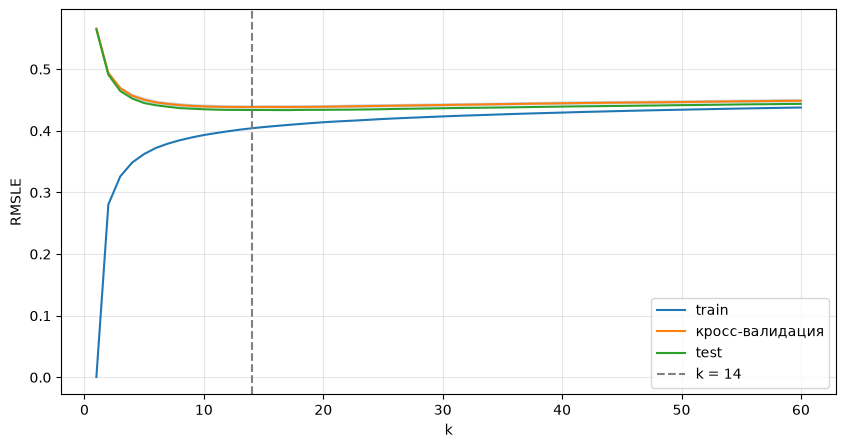

In [31]:
preprocessor = make_preprocessor()
X_train = preprocessor.fit_transform(train, y_train)
X_test = preprocessor.transform(test)
feature_names = preprocessor.get_feature_names_out()

train_errors = knn_errors_for_all_k(X_train, y_train, X_train, y_train)
test_errors = knn_errors_for_all_k(X_train, y_train, X_test, y_test)

plt.figure(figsize=(10, 5))
plt.plot(ks, train_errors, label='train')
plt.plot(ks, cv_mean, label='кросс-валидация')
plt.fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, alpha=0.3)
plt.plot(ks, test_errors, label='test')
plt.axvline(best_k, color='gray', linestyle='--', label=f'k = {best_k}')
plt.xlabel('k')
plt.ylabel('RMSLE')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [32]:
const_pred = np.full_like(y_test, y_train.mean())
errors_table = {
    ('константа (среднее log-цены)', 'train'): report(y_train, np.full_like(y_train, y_train.mean())),
    ('константа (среднее log-цены)', 'test'): report(y_test, const_pred),
}
for k in [1, best_k]:
    model = KNeighborsRegressor(n_neighbors=k, n_jobs=-1).fit(X_train, y_train)
    errors_table[(f'kNN, k = {k}', 'train')] = report(y_train, model.predict(X_train))
    errors_table[(f'kNN, k = {k}', 'test')] = report(y_test, model.predict(X_test))
knn_best = model
pred_test_knn = knn_best.predict(X_test)
pd.DataFrame(errors_table).T.round(3)

RMSLE  R2 (log)    MAE, $  R2 ($)
константа (среднее log-цены) train  0.858     0.000  9428.603  -0.111
                             test   0.857    -0.000  9388.895  -0.109
kNN, k = 1                   train  0.001     1.000     0.126   1.000
                             test   0.565     0.565  5039.538   0.569
kNN, k = 14                  train  0.404     0.778  3734.942   0.741
                             test   0.434     0.744  3973.160   0.720

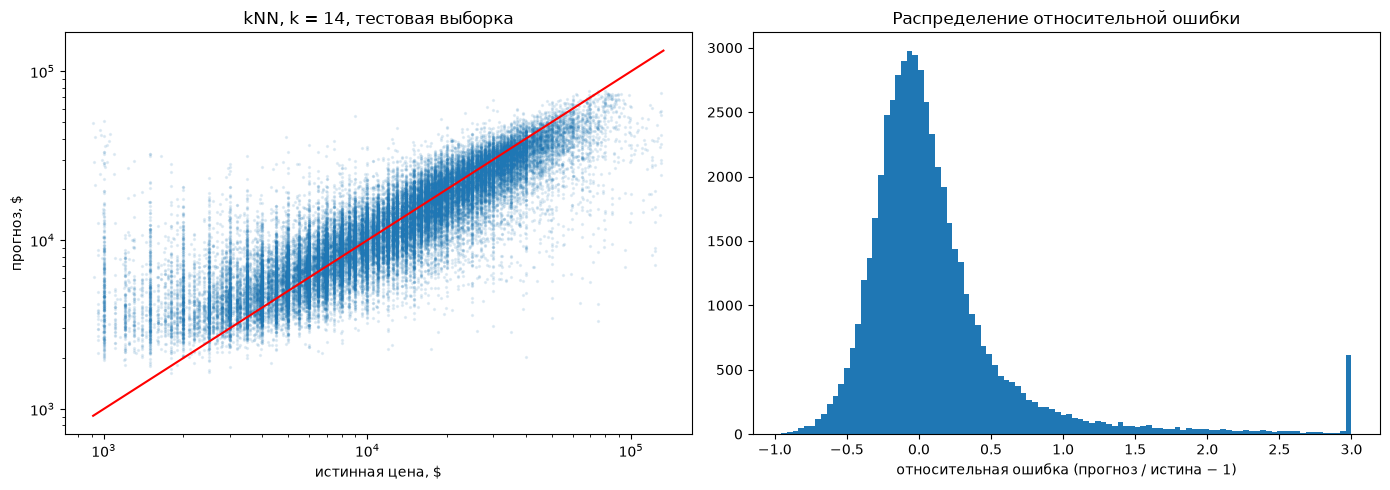

Медианная абсолютная относительная ошибка: 20.7%
Ошибка не больше 20%: 48.6% объектов


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(np.exp(y_test), np.exp(pred_test_knn), s=2, alpha=0.1)
axes[0].plot([PRICE_MIN, PRICE_MAX], [PRICE_MIN, PRICE_MAX], color='r')
axes[0].set(xscale='log', yscale='log', xlabel='истинная цена, $', ylabel='прогноз, $',
            title=f'kNN, k = {best_k}, тестовая выборка')
rel_error = np.exp(pred_test_knn - y_test) - 1
axes[1].hist(np.clip(rel_error, -1, 3), bins=100)
axes[1].set(xlabel='относительная ошибка (прогноз / истина − 1)', title='Распределение относительной ошибки')
plt.tight_layout()
plt.show()
print(f'Медианная абсолютная относительная ошибка: {np.median(np.abs(rel_error)):.1%}')
print(f'Ошибка не больше 20%: {(np.abs(rel_error) <= 0.2).mean():.1%} объектов')

**Train и test.** При $k = 1$ ошибка на train почти нулевая (0.001), а на test 0.565. Модель просто запомнила обучающую выборку, это классическое переобучение. С ростом $k$ ошибка на train растёт, а на кросс-валидации и тесте падает и достигает минимума около $k = 14$. Дальше она медленно растёт, начинается недообучение. Минимум пологий: при $k$ от 10 до 30 ошибка почти одинаковая.

Кривые кросс-валидации и теста почти совпадают, так что оценке по кросс-валидации можно доверять.

**Итог при $k = 14$.** RMSLE на тесте 0.434, тогда как константный прогноз даёт 0.857. $R^2$ равен 0.74 в логарифмической шкале и 0.72 в долларах, MAE около 3 970 $. Ошибки на train и test различаются несильно (0.404 и 0.434), так что заметного переобучения нет.

Типичная относительная ошибка около 20%: у половины машин прогноз отличается от цены не больше чем на 20%. По графику видно, что дешёвые машины модель систематически переоценивает, а дорогие недооценивает. Подробнее об этом в разделе 11.

## 10. (по желанию) Другие модели

Сравним kNN с другими моделями на тех же признаках. Деревьям нормализация не нужна, но и не мешает. Гиперпараметры взяты разумные, без тщательного подбора.

In [34]:
models = {
    'константа': DummyRegressor(),
    'Ridge (линейная регрессия)': Ridge(alpha=1.0),
    f'kNN, k = {best_k}': KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1),
    f'kNN, k = {best_k}, веса 1/расстояние': KNeighborsRegressor(n_neighbors=best_k, weights='distance', n_jobs=-1),
    'решающее дерево': DecisionTreeRegressor(min_samples_leaf=10, random_state=RANDOM_STATE),
    'случайный лес': RandomForestRegressor(n_estimators=100, max_features=0.5, min_samples_leaf=2,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    'градиентный бустинг (HistGB)': HistGradientBoostingRegressor(max_iter=500, random_state=RANDOM_STATE),
}
rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    rows[name] = {'RMSLE train': root_mean_squared_error(y_train, model.predict(X_train)),
                  **report(y_test, model.predict(X_test))}
pd.DataFrame(rows).T.round(3)

,RMSLE train,RMSLE,R2 (log),"MAE, $",R2 ($)
константа,0.858,0.857,-0.000,9388.895,-0.109
Ridge (линейная регрессия),0.500,0.500,0.660,4786.093,0.622
"kNN, k = 14",0.404,0.434,0.744,3973.160,0.720
"kNN, k = 14, веса 1/расстояние",0.000,0.428,0.750,3873.076,0.729
решающее дерево,0.339,0.453,0.720,4033.667,0.717
случайный лес,0.200,0.380,0.803,3193.758,0.792
градиентный бустинг (HistGB),0.340,0.367,0.816,3215.389,0.794


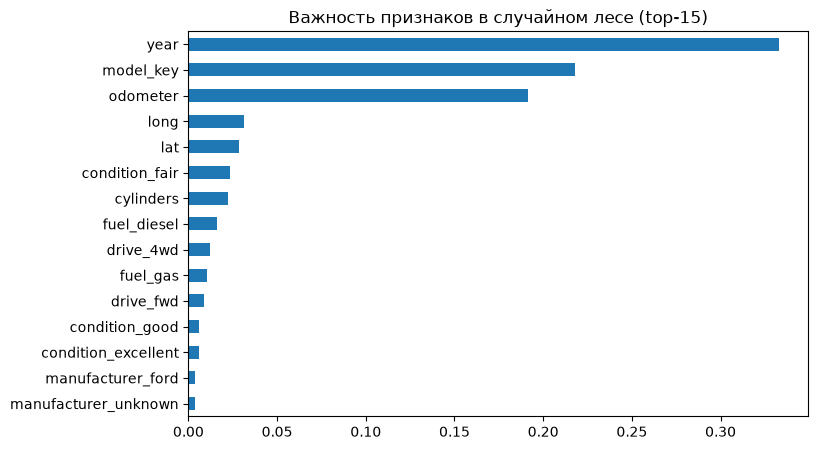

In [35]:
importances = pd.Series(models['случайный лес'].feature_importances_, index=feature_names)
importances.nlargest(15).sort_values().plot.barh(figsize=(8, 5))
plt.title('Важность признаков в случайном лесе (top-15)')
plt.show()

Все модели заметно лучше константы. Линейная регрессия (Ridge) уступает kNN (RMSLE 0.50 против 0.434), потому что цена зависит от года и пробега нелинейно; вспомним хотя бы коллекционные машины.

kNN с весами $1/\text{расстояние}$ работает чуть лучше обычного (0.428). Нулевая ошибка на train у него ничего не значит: ближайшим соседом объекта оказывается он сам, на нулевом расстоянии и с бесконечным весом. Одиночное дерево переобучается: 0.34 на train и 0.45 на test.

Лучше всех справились ансамбли деревьев: случайный лес (RMSLE 0.380, $R^2$ = 0.80) и градиентный бустинг (0.367, $R^2$ = 0.82, MAE около 3 200 $). Деревья сами выбирают важные признаки и пороги, а kNN учитывает все сто с лишним признаков с теми весами, которые задали мы.

Для случайного леса важнее всего год выпуска, модель (target encoding) и пробег. За ними идут координаты, состояние, число цилиндров, топливо и привод. Цвет в первую пятнадцатку не попал.

## 11. (по желанию) Несбалансированность

В регрессии несбалансированность означает, что целевая переменная распределена неравномерно. Половина машин стоит от 6 до 21 тысячи долларов, а очень дешёвых и очень дорогих мало (вспомним гистограмму из раздела 4). kNN усредняет цены соседей, и рядом с редкой дорогой машиной неизбежно оказываются более частые и дешёвые. В итоге прогнозы «стягиваются» к типичной цене.

Проверим это по ценовым сегментам на валидационной части обучающей выборки. Заодно попробуем простой приём под названием **oversampling**: разобьём диапазон log(price) на 20 равных интервалов и будем дублировать случайные объекты из малочисленных интервалов, пока те не дорастут до медианного размера. Дублируем уже после кодирования признаков, чтобы копии не исказили target encoding.

In [36]:
def oversample_rare_prices(y, n_bins=20):
    """Индексы объектов, в которых редкие интервалы log(price) дополнены случайными повторами."""
    rng = np.random.default_rng(RANDOM_STATE)
    bins = np.linspace(y.min(), y.max(), n_bins + 1)
    bin_id = np.clip(np.digitize(y, bins) - 1, 0, n_bins - 1)
    target = int(np.median(np.bincount(bin_id, minlength=n_bins)))
    idx = [np.arange(len(y))]
    for b in range(n_bins):
        members = np.flatnonzero(bin_id == b)
        if 0 < len(members) < target:
            idx.append(rng.choice(members, target - len(members)))
    return np.concatenate(idx)


prep = make_preprocessor()
X_tr_part = prep.fit_transform(tr_part, y_tr_part)
X_val_part = prep.transform(val_part)
os_idx = oversample_rare_prices(y_tr_part)
print(f'Обучающих объектов: {len(y_tr_part)} -> {len(os_idx)} после oversampling')

segments = pd.cut(np.exp(y_val_part), [0, 3_000, 10_000, 30_000, 60_000, np.inf],
                  labels=['< 3k', '3–10k', '10–30k', '30–60k', '> 60k'])
segment_tables, overall = {}, {}
for name, (X_fit, y_fit) in {'исходная выборка': (X_tr_part, y_tr_part),
                             'oversampling': (X_tr_part[os_idx], y_tr_part[os_idx])}.items():
    error = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1).fit(X_fit, y_fit).predict(X_val_part) - y_val_part
    by_segment = pd.Series(error).groupby(segments, observed=True)
    segment_tables[name] = pd.DataFrame({
        'объектов': by_segment.size(),
        'смещение, %': (np.exp(by_segment.mean()) - 1) * 100,
        'RMSLE': by_segment.apply(lambda e: np.sqrt(np.mean(e ** 2))),
    })
    overall[name] = np.sqrt(np.mean(error ** 2))

display(pd.concat(segment_tables, axis=1).round(3))
pd.Series(overall, name='RMSLE на всей валидации').round(4)

Обучающих объектов: 128448 -> 167997 после oversampling


исходная выборка                    oversampling                   
               объектов смещение, %  RMSLE     объектов смещение, %  RMSLE
< 3k               2418     120.752  0.983         2418      74.011  0.883
3–10k             12116      11.785  0.353        12116       0.568  0.458
10–30k            13633      -8.496  0.314        13633      -9.491  0.432
30–60k             3533     -21.041  0.388         3533     -14.160  0.456
> 60k               412     -48.523  0.884          412     -36.730  0.836

исходная выборка    0.4339
oversampling        0.4989
Name: RMSLE на всей валидации, dtype: float64

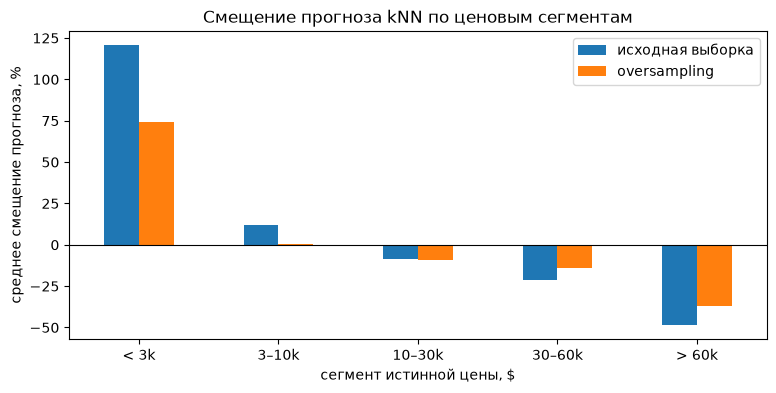

In [37]:
bias = pd.DataFrame({name: t['смещение, %'] for name, t in segment_tables.items()})
bias.plot.bar(figsize=(9, 4), rot=0)
plt.axhline(0, color='k', linewidth=0.8)
plt.ylabel('среднее смещение прогноза, %')
plt.xlabel('сегмент истинной цены, $')
plt.title('Смещение прогноза kNN по ценовым сегментам')
plt.show()

**Проблема подтверждается.** Обычный kNN завышает цену самых дешёвых машин (до 3 000 $) в среднем больше чем вдвое (+121%), а цену самых дорогих (от 60 000 $) занижает почти вдвое (−49%). Ошибка в крайних сегментах (RMSLE 0.98 и 0.88) в два или три раза больше, чем в середине.

**Oversampling** уменьшает смещение в крайних сегментах (до +74% и −37%) и немного снижает там ошибку. Но прогноз в многочисленных средних сегментах становится хуже, и общая ошибка растёт с 0.434 до 0.499. Поэтому в итоговую модель oversampling не берём. Он имеет смысл, только если нам важнее точность именно на редких дешёвых или дорогих машинах.

Часть смещения в дешёвом сегменте, скорее всего, не вина модели. Среди машин дешевле 3 000 $ попадаются объявления с символической «приманочной» ценой вроде первого взноса, которые прошли через фильтр выбросов.

Несбалансированность есть и в категориальных признаках: у Ferrari, Aston Martin, Morgan и электромобилей объявлений единицы или десятки. Это мы уже частично учли, когда объединяли редкие категории при one-hot кодировании и сглаживали target encoding.

## 12. (по желанию) Коррелированные признаки

Для kNN сильно коррелированные признаки по сути дублируют друг друга. Одно и то же различие попадает в расстояние дважды, и этот фактор получает двойной вес. Посмотрим, как количественные признаки связаны с целевой переменной, и поищем сильно коррелированные пары среди всех признаков после кодирования.

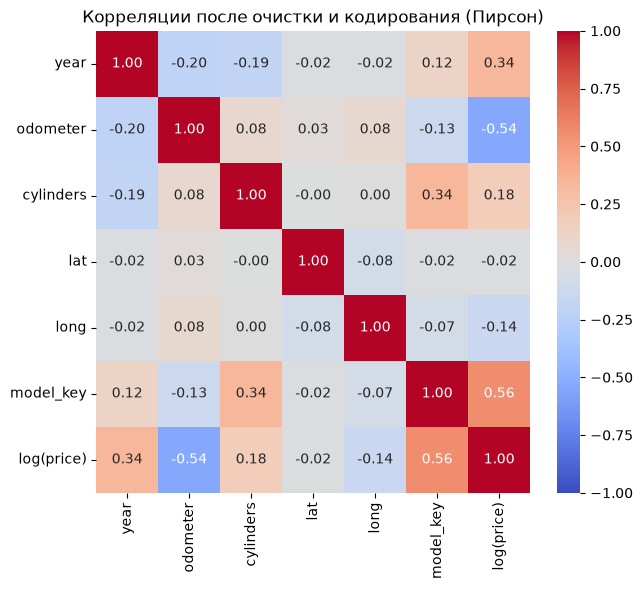

In [38]:
X_train_df = pd.DataFrame(X_train, columns=feature_names)
corr_cols = num_features + te_features
corr = X_train_df[corr_cols].assign(**{'log(price)': y_train}).corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляции после очистки и кодирования (Пирсон)')
plt.show()

In [39]:
corr_all = X_train_df.corr()
upper = corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1))
pairs = upper.stack().rename('r').reset_index()
print('Пар с |r| > 0.7:', (pairs['r'].abs() > 0.7).sum())
pairs = pairs[pairs['r'].abs() > 0.5].sort_values('r', key=abs, ascending=False)
target_corr = X_train_df.corrwith(pd.Series(y_train)).abs()
pairs['|r| с ценой 1'] = pairs['level_0'].map(target_corr).round(3)
pairs['|r| с ценой 2'] = pairs['level_1'].map(target_corr).round(3)
pairs.round(3)

Пар с |r| > 0.7: 1


,level_0,level_1,r,|r| с ценой 1,|r| с ценой 2
7063,transmission_automatic,transmission_manual,-0.754,0.056,0.065
5673,fuel_diesel,fuel_gas,-0.695,0.192,0.223
6317,title_status_clean,title_status_rebuilt,-0.629,0.039,0.026
8028,size_full-size,size_unknown,-0.626,0.025,0.128
7064,transmission_automatic,transmission_other,-0.578,0.056,0.165
9643,type_unknown,paint_color_unknown,0.521,0.110,0.065
5887,fuel_gas,fuel_other,-0.518,0.223,0.126


Количественные признаки между собой связаны слабо. Самая сильная корреляция, 0.34, между числом цилиндров и кодировкой модели. Интересно, что корреляция Пирсона между годом и пробегом всего −0.20, хотя ранговая в разделе 3 была −0.54. А корреляция года с log(price) лишь 0.34, при том что для случайного леса год оказался самым важным признаком. Обе зависимости нелинейные, во многом из-за старых коллекционных машин, и коэффициент Пирсона их недооценивает.

Пар с $|r| > 0.7$ нашлась всего одна (`transmission_automatic` и `transmission_manual`), поэтому мы снизили порог до 0.5. Почти все найденные пары состоят из бинарных столбцов одного и того же исходного признака. Такие столбцы взаимоисключающие и потому коррелируют отрицательно, особенно когда у признака два преобладающих значения (`automatic` и `manual`, `gas` и `diesel`, `clean` и `rebuilt`, `full-size` и `unknown`). Только одна пара собрана из разных признаков: `type_unknown` и `paint_color_unknown`. Пропуски в объявлениях появляются группами, мы это видели в разделе 5.

In [40]:
# из каждой пары удаляем признак, слабее связанный с ценой
to_drop = sorted({a if target_corr[a] < target_corr[b] else b for a, b in zip(pairs['level_0'], pairs['level_1'])})
print('Удаляем:', to_drop)
cv_errors_drop = cv_knn_errors(drop_features=to_drop)

pd.DataFrame({
    'все признаки': [cv_mean.min(), ks[cv_mean.argmin()]],
    'без коррелированных': [cv_errors_drop.mean(axis=0).min(), ks[cv_errors_drop.mean(axis=0).argmin()]],
}, index=['RMSLE (CV)', 'лучшее k']).round(4)

Удаляем: ['fuel_diesel', 'fuel_other', 'paint_color_unknown', 'size_full-size', 'title_status_rebuilt', 'transmission_automatic']


,все признаки,без коррелированных
RMSLE (CV),0.4385,0.4403
лучшее k,14.0000,16.0000


Удаление коррелированных столбцов немного **ухудшило** качество: RMSLE на кросс-валидации выросла с 0.4385 до 0.4403. Разница примерно равна разбросу между фолдами (±0.003).

Этого и стоило ожидать. Сильно коррелированных *разных* признаков в данных нет, а найденные пары принадлежат одному one-hot кодированию. Убирая один столбец из пары, мы не избавляемся от дублирования, а просто произвольно меняем вклад признака в расстояние. Например, без `transmission_automatic` машины с автоматом и с механикой различаются уже в одном столбце вместо двух. Поэтому оставляем все признаки.

## 13. Выводы

1. **Данные.** Датасет Craigslist оказался сильно «грязным». 44% объявлений повторяют одни и те же машины, у 10% нереальная цена (0 $, 1 $, миллиарды), в пробеге и координатах попадаются заглушки, а в некоторых признаках пропущено от четверти до почти двух третей значений. Без удаления дубликатов ошибка kNN на тесте была бы заниженной, а без фильтрации цен её определяли бы абсурдные значения.
2. **Предобработка.** Предсказываем log(price): цена сильно скошена, а ошибка в логарифмах соответствует относительной. Пропуски в категориальных признаках оказались информативными, поэтому стали отдельной категорией. Координаты заполняем по штату. Категориальные признаки кодируем через one-hot, а модель машины с её тысячами значений через target encoding со сглаживанием.
3. **Нормализация** для kNN критична. Стандартизация количественных признаков и согласованный вес бинарных снизили RMSLE с 0.66 до 0.435.
4. **kNN.** Оптимальное $k = 14$ по 5-кратной кросс-валидации, причём минимум пологий, и $k$ от 10 до 30 дают почти то же самое. При $k = 1$ модель переобучается (ошибка почти 0 на train и 0.565 на test), при больших $k$ недообучается. На тестовой выборке RMSLE 0.434, $R^2$ = 0.74 в логарифмической шкале, MAE около 3 970 $, и у половины машин ошибка не больше 20%. Для сравнения, константный прогноз даёт RMSLE 0.857.
5. **Другие модели.** Ансамбли деревьев заметно точнее kNN: градиентный бустинг даёт RMSLE 0.367, $R^2$ = 0.82 и MAE около 3 200 $. Линейная регрессия хуже kNN. Главные факторы цены: год выпуска, модель и пробег.
6. **Несбалансированность.** kNN стягивает прогнозы к типичной цене, поэтому дешёвые машины переоценивает, а дорогие недооценивает. Oversampling редких ценовых диапазонов уменьшает это смещение, но общая ошибка растёт с 0.434 до 0.499.
7. **Коррелированные признаки.** Сильно коррелированных разных признаков в данных нет, а удаление коррелированных one-hot столбцов качество не улучшает.